# Baselines

Train-mean, season-to-date average, ridge, random forest and LightGBM. Train on 2021–2024, tune and report on 2025. 2026 is not loaded.

Ablation at the end: pitcher-only vs lineup-only vs combined features (plus combined + batter-vs-pitcher history when the dataset has it).

In Colab, run this first:
```
!git clone -b baselines https://github.com/elizabethahong/ML-Grad-Project.git
%cd ML-Grad-Project/baselines
```

In [1]:
import itertools
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from data import BVP_FEATURES, FEATURES, load_splits
from eval import TARGETS, compare, evaluate

SEED = 0
warnings.filterwarnings("ignore", category=FutureWarning)
splits = load_splits()
train, val = splits["train"], splits["val"]
Y_tr, Y_va = train[TARGETS], val[TARGETS]

FEATURE_SETS = {
    "pitcher only": [c for c in FEATURES if not c.startswith("lu_")],
    "lineup only": [c for c in FEATURES if not c.startswith("p_")],
    "combined": FEATURES,
}
# only when the dataset has batter-vs-pitcher columns
if BVP_FEATURES:
    FEATURE_SETS["combined + bvp"] = FEATURES + BVP_FEATURES
print(len(train), len(val), {k: len(v) for k, v in FEATURE_SETS.items()})

19436 4860 {'pitcher only': 21, 'lineup only': 8, 'combined': 28}


In [2]:
def rmse(y, p):
    return np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2))


results, preds = {}, {}

preds["train mean"] = np.tile(Y_tr.mean().values, (len(val), 1))

# pitcher's season-to-date average (last-5 average for his first start of the season)
preds["season avg"] = val[["p_std_h", "p_std_k", "p_std_bb", "p_std_er"]].values

for name in preds:
    results[name] = evaluate(Y_va, preds[name])

## Models

In [3]:
# each returns 2025 predictions (n, 4), fitted models, chosen settings, and seconds to fit the final models

def fit_ridge(cols):
    X_tr, X_va = train[cols], val[cols]
    alphas = np.logspace(-2, 5, 15)
    best = {}
    for t in TARGETS:
        scores = [rmse(Y_va[t], make_pipeline(StandardScaler(), Ridge(alpha=a))
                       .fit(X_tr, Y_tr[t]).predict(X_va)) for a in alphas]
        best[t] = alphas[int(np.argmin(scores))]
    start = time.perf_counter()
    model = make_pipeline(StandardScaler(), Ridge(alpha=[best[t] for t in TARGETS])).fit(X_tr, Y_tr)
    return model.predict(X_va), model, best, time.perf_counter() - start


def fit_rf(cols):
    X_tr, X_va = train[cols], val[cols]
    grid = {"max_depth": [8, 12], "min_samples_leaf": [5, 20, 50, 100], "max_features": [0.2, 0.33]}
    models, params, fit_s = {}, {}, {}
    for t in TARGETS:
        best = None
        for vals in itertools.product(*grid.values()):
            p = dict(zip(grid, vals))
            m = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **p)
            start = time.perf_counter()
            m.fit(X_tr, Y_tr[t])
            secs = time.perf_counter() - start
            score = rmse(Y_va[t], m.predict(X_va))
            if best is None or score < best:
                best, models[t], params[t], fit_s[t] = score, m, p, secs
    return np.column_stack([models[t].predict(X_va) for t in TARGETS]), models, params, sum(fit_s.values())


def fit_lgb(cols):
    X_tr, X_va = train[cols], val[cols]
    grid = {"num_leaves": [4, 7, 15, 31], "learning_rate": [0.02, 0.05]}
    models, params, fit_s = {}, {}, {}
    for t in TARGETS:
        best = None
        for vals in itertools.product(*grid.values()):
            p = dict(zip(grid, vals))
            m = lgb.LGBMRegressor(n_estimators=5000, min_child_samples=50, subsample=0.8,
                                  subsample_freq=1, colsample_bytree=0.8, random_state=SEED,
                                  verbose=-1, **p)
            # early stopping on 2025
            start = time.perf_counter()
            m.fit(X_tr, Y_tr[t], eval_set=[(X_va, Y_va[t])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
            secs = time.perf_counter() - start
            score = rmse(Y_va[t], m.predict(X_va))
            if best is None or score < best:
                best, models[t], params[t], fit_s[t] = score, m, {**p, "trees": m.best_iteration_}, secs
    return np.column_stack([models[t].predict(X_va) for t in TARGETS]), models, params, sum(fit_s.values())


MODELS = {"ridge": fit_ridge, "random forest": fit_rf, "lightgbm": fit_lgb}

In [4]:
# takes ~20 min, mostly the random forest grid
ablation, fitted, compute = {}, {}, {}
for set_name, cols in FEATURE_SETS.items():
    for model_name, fit in MODELS.items():
        start = time.perf_counter()
        p, models, params, fit_s = fit(cols)
        tune_s = time.perf_counter() - start
        ablation[(model_name, set_name)] = evaluate(Y_va, p)
        fitted[(model_name, set_name)] = models
        print(model_name, "|", set_name, "|", params)
        if set_name == "combined":
            compute[model_name] = {"final fit (s)": fit_s, "full tuning (s)": tune_s}
            preds[model_name] = p
            results[model_name] = evaluate(Y_va, p)

ridge | pitcher only | {'hits': np.float64(1000.0), 'strikeouts': np.float64(31.622776601683793), 'walks': np.float64(0.01), 'earned_runs': np.float64(3162.2776601683795)}


random forest | pitcher only | {'hits': {'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 0.33}, 'strikeouts': {'max_depth': 12, 'min_samples_leaf': 50, 'max_features': 0.33}, 'walks': {'max_depth': 12, 'min_samples_leaf': 50, 'max_features': 0.2}, 'earned_runs': {'max_depth': 12, 'min_samples_leaf': 20, 'max_features': 0.2}}


lightgbm | pitcher only | {'hits': {'num_leaves': 7, 'learning_rate': 0.02, 'trees': 365}, 'strikeouts': {'num_leaves': 7, 'learning_rate': 0.02, 'trees': 268}, 'walks': {'num_leaves': 4, 'learning_rate': 0.02, 'trees': 339}, 'earned_runs': {'num_leaves': 15, 'learning_rate': 0.02, 'trees': 320}}


ridge | lineup only | {'hits': np.float64(3162.2776601683795), 'strikeouts': np.float64(1000.0), 'walks': np.float64(10000.0), 'earned_runs': np.float64(3162.2776601683795)}


random forest | lineup only | {'hits': {'max_depth': 8, 'min_samples_leaf': 20, 'max_features': 0.2}, 'strikeouts': {'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 0.33}, 'walks': {'max_depth': 12, 'min_samples_leaf': 100, 'max_features': 0.2}, 'earned_runs': {'max_depth': 12, 'min_samples_leaf': 100, 'max_features': 0.2}}


lightgbm | lineup only | {'hits': {'num_leaves': 15, 'learning_rate': 0.02, 'trees': 166}, 'strikeouts': {'num_leaves': 4, 'learning_rate': 0.02, 'trees': 172}, 'walks': {'num_leaves': 4, 'learning_rate': 0.02, 'trees': 212}, 'earned_runs': {'num_leaves': 7, 'learning_rate': 0.05, 'trees': 49}}


ridge | combined | {'hits': np.float64(1000.0), 'strikeouts': np.float64(1000.0), 'walks': np.float64(31.622776601683793), 'earned_runs': np.float64(3162.2776601683795)}


random forest | combined | {'hits': {'max_depth': 12, 'min_samples_leaf': 20, 'max_features': 0.2}, 'strikeouts': {'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 0.33}, 'walks': {'max_depth': 12, 'min_samples_leaf': 100, 'max_features': 0.33}, 'earned_runs': {'max_depth': 12, 'min_samples_leaf': 50, 'max_features': 0.2}}


lightgbm | combined | {'hits': {'num_leaves': 4, 'learning_rate': 0.02, 'trees': 662}, 'strikeouts': {'num_leaves': 15, 'learning_rate': 0.05, 'trees': 152}, 'walks': {'num_leaves': 15, 'learning_rate': 0.05, 'trees': 54}, 'earned_runs': {'num_leaves': 15, 'learning_rate': 0.05, 'trees': 123}}


## Results on 2025 validation

In [5]:
table = compare(results).round(3)
table.to_csv("results_2025.csv")
table

target          hits        strikeouts         walks        earned_runs       
                 MAE   RMSE        MAE   RMSE    MAE   RMSE         MAE   RMSE
model                                                                         
train mean     1.765  2.221      1.979  2.471  1.060  1.289       1.613  1.984
season avg     1.842  2.321      1.907  2.414  1.084  1.361       1.660  2.117
ridge          1.719  2.133      1.768  2.224  1.013  1.256       1.574  1.952
random forest  1.717  2.130      1.767  2.225  1.016  1.257       1.576  1.952
lightgbm       1.717  2.129      1.764  2.221  1.017  1.256       1.573  1.952

## Compute (combined features, all 4 targets)

In [6]:
# final fit = training the chosen settings once; full tuning = the whole search on 2025
comp = pd.DataFrame(compute).T.round(2)
comp.index.name = "model"
comp.to_csv("compute_2025.csv")
comp

,final fit (s),full tuning (s)
model,,
ridge,0.01,0.51
random forest,13.52,190.77
lightgbm,3.13,27.36


## Ablation: pitcher-only vs lineup-only vs combined

In [7]:
abl = pd.DataFrame({k: v["RMSE"] for k, v in ablation.items()}).T
abl.index.names = ["model", "features"]
abl = abl.reindex(pd.MultiIndex.from_product([MODELS, FEATURE_SETS], names=abl.index.names))
abl.round(3).to_csv("ablation_2025.csv")
abl.round(3)

target                       hits  strikeouts  walks  earned_runs
model         features                                           
ridge         pitcher only  2.138       2.266  1.261        1.956
              lineup only   2.217       2.429  1.284        1.979
              combined      2.133       2.224  1.256        1.952
random forest pitcher only  2.132       2.263  1.262        1.956
              lineup only   2.216       2.433  1.285        1.979
              combined      2.130       2.225  1.257        1.952
lightgbm      pitcher only  2.132       2.264  1.261        1.955
              lineup only   2.216       2.430  1.284        1.978
              combined      2.129       2.221  1.256        1.952

In [8]:
# % RMSE reduction from adding lineup features to pitcher-only
gain = {m: 100 * (1 - abl.loc[(m, "combined")] / abl.loc[(m, "pitcher only")]) for m in MODELS}
pd.DataFrame(gain).T.round(2)

target,hits,strikeouts,walks,earned_runs
ridge,0.24,1.84,0.40,0.22
random forest,0.09,1.68,0.39,0.19
lightgbm,0.15,1.91,0.40,0.16


In [ ]:
# % RMSE reduction from adding batter-vs-pitcher history to combined
if BVP_FEATURES:
    bvp_gain = {m: 100 * (1 - abl.loc[(m, "combined + bvp")] / abl.loc[(m, "combined")]) for m in MODELS}
    display(pd.DataFrame(bvp_gain).T.round(2))

## Feature importance (combined features)

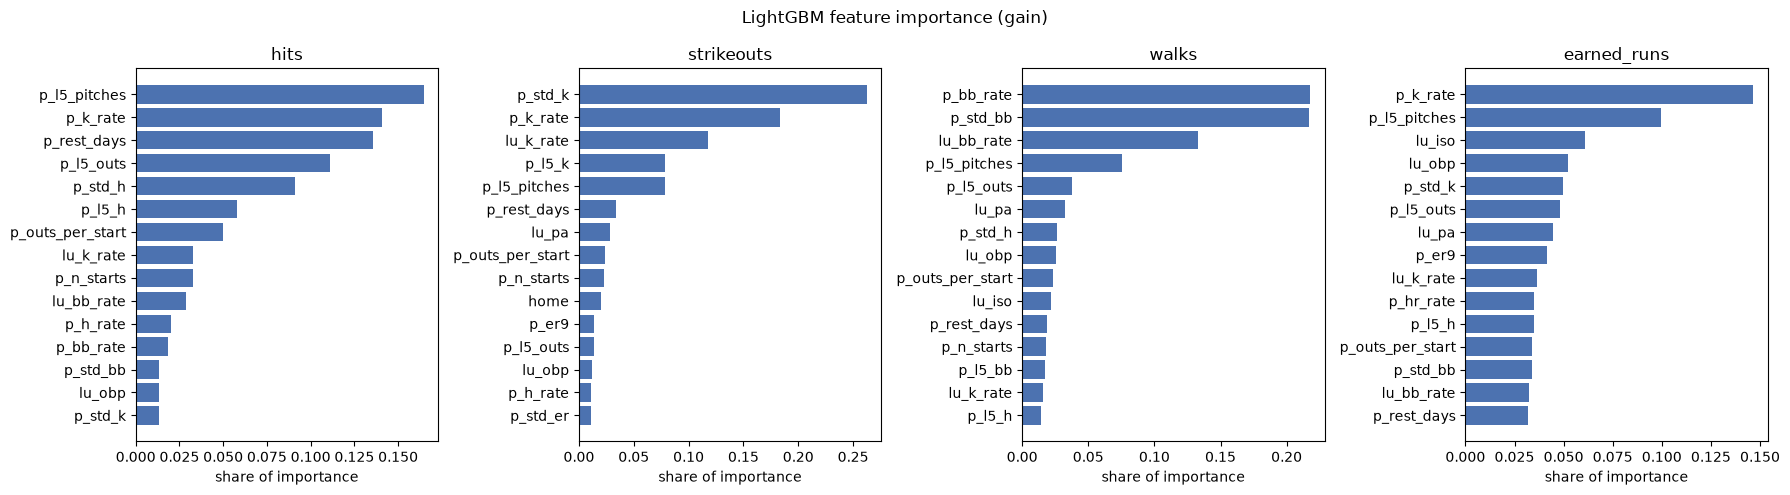

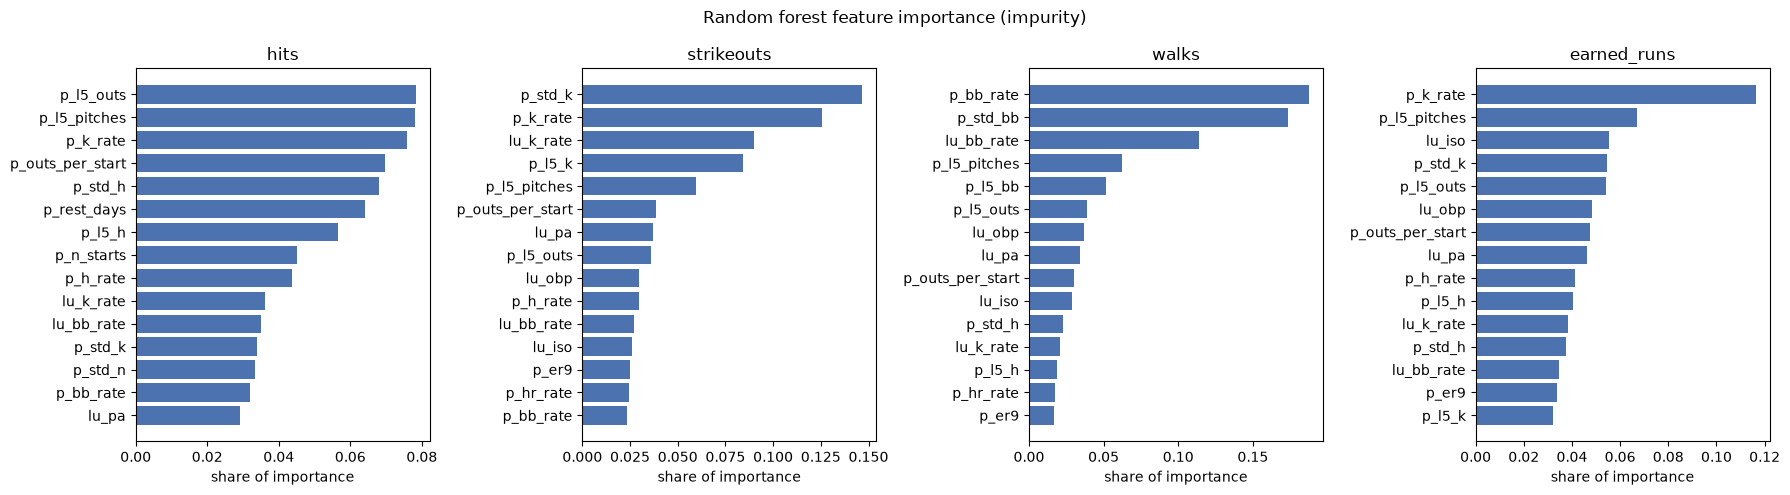

In [9]:
def plot_importance(models, title, path, top=15):
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    for ax, t in zip(axes, TARGETS):
        m = models[t]
        imp = m.booster_.feature_importance("gain") if hasattr(m, "booster_") else m.feature_importances_
        imp = pd.Series(imp / imp.sum(), index=FEATURES).sort_values().tail(top)
        ax.barh(imp.index, imp.values, color="#4C72B0")
        ax.set_title(t)
        ax.set_xlabel("share of importance")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


plot_importance(fitted[("lightgbm", "combined")], "LightGBM feature importance (gain)", "feature_importance_lgbm.png")
plot_importance(fitted[("random forest", "combined")], "Random forest feature importance (impurity)", "feature_importance_rf.png")